In [1]:
# SPDX-FileCopyrightText: 2024-2026 Dan J. Bower <dbower@eaps.ethz.ch>
# SPDX-FileCopyrightText: 2024-2026 Paolo A. Sossi
#
# SPDX-License-Identifier: Apache-2.0

import time

import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from jaxtyping import Array, ArrayLike, Bool, Float
from matplotlib.lines import Line2D

from atmodeller import (
    ChemicalSpecies,
    EquilibriumModel,
    IronWustiteBuffer,
    Output,
    Planet,
    ReservoirSpecies,
    get_solubility_models,
)

# Updating a model in a loop

This notebook is available at `notebooks/examples/updating_models.ipynb` and is easiest to obtain by downloading the source code.

*Atmodeller* is built on [JAX](https://docs.jax.dev/en/latest/), and this notebook briefly introduces some of the features of JAX that *Atmodeller* can exploit for performance: compilation with `jit`, reusing compiled code, and loops with `jax.lax.scan`. It is only an overview. To make the most of JAX, we recommend that you become familiar with its capabilities in detail, from the [JAX documentation](https://docs.jax.dev/en/latest/) and the many tutorials and other resources available online.

Many applications solve the same model many times with different inputs, for example to follow the evolution of a planet. Building a model and solving it for the first time compiles the solver, which takes seconds. Each later solve with the same structure reuses the compiled solver and takes milliseconds, as long as the model is changed with its update methods rather than built again:

- `model.update_state(...)` changes the thermodynamic state, e.g. `temperature`, `pressure`, `planet_mass` or `mantle_melt_fraction`.
- `model.update_constraints(...)` changes the mass constraints, keyed by element, and the values of the activity constraints, e.g. the `log10_shift` of a buffer.

Both take keyword arguments and return a new model with the same structure, so the arrays keep their shapes and nothing is compiled again. For the full list of what can be updated, see [Updating a model](../updating.rst) in the documentation.

As an example, we follow the loss of hydrogen from the atmospheres of a batch of planets with magma oceans. At each step, 3% of the hydrogen in the atmosphere escapes, and the rest re-equilibrates with the magma ocean, which dissolves H<sub>2</sub>O and buffers the atmosphere. We solve this in three ways, each faster than the last:

1. A Python loop that solves each step from a cold start.
2. A Python loop that starts each step from the previous solution (a warm start).
3. A `jax.lax.scan` over the steps, compiled as a whole with `jit`.

Functions are compiled with `equinox.filter_jit` rather than `jax.jit`. The two are the same transformation, but `filter_jit` is designed for [Equinox](https://docs.kidger.site/equinox/) modules, which *Atmodeller* uses throughout: the model and its output are Equinox modules that hold arrays together with other Python objects, such as the names of the species, Python numbers and functions. `jax.jit` traces every argument as an array, so it fails on these objects, whereas `filter_jit` traces only the arrays and treats everything else as static. See the [Equinox documentation](https://docs.kidger.site/equinox/api/transformations/#equinox.filter_jit) for further information.

## The model

The planets have an atmosphere of H<sub>2</sub>O, H<sub>2</sub>, O<sub>2</sub>, CO, CO<sub>2</sub> and CH<sub>4</sub> over a magma ocean at 1800 K with a melt fraction of 0.1. The oxygen fugacity is set by the iron-wüstite buffer, and the planets have between one and five Earth oceans of hydrogen and 10<sup>20</sup> kg of carbon. The model is built once, for the whole batch.

In [2]:
solubility_models = get_solubility_models()

gas_species = tuple(
    ChemicalSpecies.create_gas(formula) for formula in ("H2O", "H2", "O2", "CO", "CO2", "CH4")
)
melt_species = (
    ReservoirSpecies.create_dissolved(
        "H2O", solubility=solubility_models["H2O_peridotite_sossi23"]
    ),
    ReservoirSpecies.create_dissolved("CO2", solubility=solubility_models["CO2_basalt_dixon95"]),
)
planet = Planet.from_species(
    gas_species, silicate_melt_species=melt_species, temperature=1800, mantle_melt_fraction=0.1
)

OCEAN_H_MASS = 1.55e20  # kg of hydrogen in one Earth ocean
NUMBER_OF_PLANETS = 100
initial_H_mass = OCEAN_H_MASS * jnp.linspace(1, 5, NUMBER_OF_PLANETS)

model = EquilibriumModel.from_state(
    planet,
    activity_constraints={"O2_g": IronWustiteBuffer()},
    mass_constraints={"H": initial_H_mass, "C": 1e20},
)

loss_fraction = 0.03  # Fraction of the atmospheric hydrogen lost at each step
NUMBER_OF_STEPS = 50

At each step we need the mass of hydrogen in the atmosphere. The output arrays have the batch dimension first, and each element of a phase is a column, so the mass of H in the gas has the shape `(batch, 1)`. We take the column to get one value per planet, as for the mass constraint.

The function is compiled with `equinox.filter_jit` (see above). Outside `jit`, `to_dict` computes every output quantity one operation at a time, which takes a large fraction of a second for this model, whereas compiled, only the quantities that are used are computed, in well under a millisecond. Anything called at every step of a loop is best compiled like this.

In [3]:
@eqx.filter_jit
def atmospheric_H_mass(output: Output) -> Float[Array, " n_planets"]:
    """Mass of hydrogen in the atmosphere of each planet (kg)"""
    return output.to_dict()["gas"]["elements"]["mass"]["H"][:, 0]

The first solve compiles the solver, which takes a few seconds, and the first call of `atmospheric_H_mass` compiles it. JAX dispatches work asynchronously: a call returns before its result is computed. `block_until_ready` waits for the result, so that the time taken is measured correctly. It is only needed here for timing, and would not ordinarily be included in production code, since JAX waits for a result anyway when it is needed, e.g. to print or save it. The timings shown are from building this documentation, and depend on the machine: the ratios between them matter more than their values.

In [4]:
start = time.perf_counter()
output = model.solve_with_default()
atmospheric_H_mass(output).block_until_ready()
print(f"First solve, including compilation: {time.perf_counter() - start:.2f} s")

First solve, including compilation: 5.02 s


## 1. A Python loop with cold starts

At each step, the mass constraint on H is updated to the hydrogen that remains, and the model is solved with `solve_with_default`, which starts from the initializer's guess (a cold start). Since the model keeps its structure, the solver is not compiled again. A model that fails to solve does not raise an error, so whether every solve succeeded is collected from `output.checked_solution.success`.

The whole loop is timed, and `block_until_ready` waits for the hydrogen mass of the last step, which depends on all the steps before it. As above, it is only there for the timing.

In [5]:
def evolve_cold(
    model: EquilibriumModel, loss_fraction: ArrayLike
) -> tuple[Float[Array, " n_planets"], Bool[Array, " n_planets"]]:
    """Follows the loss of hydrogen with a cold start at each step

    Returns the final hydrogen mass and whether every solve of each planet succeeded.
    """
    H_mass = initial_H_mass
    success = jnp.ones(NUMBER_OF_PLANETS, dtype=bool)
    for _ in range(NUMBER_OF_STEPS):
        updated_model = model.update_constraints(mass_constraints={"H": H_mass})
        output = updated_model.solve_with_default()
        success = success & output.checked_solution.success
        H_mass = H_mass - loss_fraction * atmospheric_H_mass(output)

    return H_mass, success


start = time.perf_counter()
H_mass_cold, success = evolve_cold(model, loss_fraction)
H_mass_cold.block_until_ready()
total_time = time.perf_counter() - start
print(
    f"Cold starts: {total_time:.3f} s in total, {total_time / NUMBER_OF_STEPS * 1e3:.1f} ms per step"
)
print(f"Every solve succeeded: {bool(jnp.all(success))}")

Cold starts: 0.789 s in total, 15.8 ms per step
Every solve succeeded: True


Each step takes milliseconds rather than seconds. The time includes updating the model in Python and getting the hydrogen from the output, as well as the solve.

## 2. A Python loop with warm starts

Consecutive steps are close to each other, so the solution of one step is a good initial guess for the next. Passing the previous `output.solution` to `solve` skips the initializer and usually needs fewer solver steps.

In [6]:
def evolve_warm(
    model: EquilibriumModel,
    initial_guess: Float[Array, "n_planets solution"],
    loss_fraction: ArrayLike,
) -> tuple[Float[Array, " n_planets"], Bool[Array, " n_planets"]]:
    """Follows the loss of hydrogen, starting each step from the previous solution

    Returns the final hydrogen mass and whether every solve of each planet succeeded.
    """
    H_mass = initial_H_mass
    success = jnp.ones(NUMBER_OF_PLANETS, dtype=bool)
    for _ in range(NUMBER_OF_STEPS):
        updated_model = model.update_constraints(mass_constraints={"H": H_mass})
        output = updated_model.solve(initial_guess)
        success = success & output.checked_solution.success
        initial_guess = output.solution
        H_mass = H_mass - loss_fraction * atmospheric_H_mass(output)

    return H_mass, success


initial_guess = model.solve_with_default().solution

start = time.perf_counter()
H_mass_warm, success = evolve_warm(model, initial_guess, loss_fraction)
H_mass_warm.block_until_ready()
total_time = time.perf_counter() - start
print(
    f"Warm starts: {total_time:.3f} s in total, {total_time / NUMBER_OF_STEPS * 1e3:.1f} ms per step"
)
print(f"Every solve succeeded: {bool(jnp.all(success))}")
print(
    f"Largest relative difference from the cold starts: {jnp.max(jnp.abs(H_mass_warm / H_mass_cold - 1)):.1e}"
)

Warm starts: 0.686 s in total, 13.7 ms per step
Every solve succeeded: True
Largest relative difference from the cold starts: 1.3e-15


The results are the same, to within the solver tolerance. Here the gain is modest, because the initializer already gives a guess that the solver needs only one or two steps to refine. It is larger for models that are harder to solve, e.g. with condensates or real gases.

## 3. `jax.lax.scan`, compiled with `jit`

The Python loop calls the compiled solver once per step, and runs the update and the output in Python between the calls. Instead, the whole evolution can be written as a JAX function and compiled once. `jax.lax.scan` replaces the loop: it carries the hydrogen mass and the initial guess from one step to the next, and collects the hydrogen mass, the atmospheric hydrogen and the success of the solve at each step. The update methods and the solve work with traced values, so the same code runs inside `jit`. As above, `equinox.filter_jit` is used, since the model is an Equinox module. The state can be changed in the same way at each step, e.g. with `model.update_state(temperature=...)` to cool the planets as they lose hydrogen.

A solve that fails does not raise an error, so it does not stop the scan, and its result is passed on to the next step. Check the success of every solve from the collected history, as below.

The loss fraction is an argument, so that the compiled function can be called again for another loss fraction without compiling it again. It must be passed as a JAX array, e.g. `jnp.asarray(0.05)`: `filter_jit` treats a Python number as static, like the strings in the model, so each new Python number would compile the function again. The same holds for any value that changes between calls.

In [7]:
@eqx.filter_jit
def evolve_scan(
    model: EquilibriumModel,
    initial_guess: Float[Array, "n_planets solution"],
    loss_fraction: Float[Array, ""],
) -> tuple[
    Float[Array, " n_planets"],
    tuple[
        Float[Array, "n_steps n_planets"],
        Float[Array, "n_steps n_planets"],
        Bool[Array, "n_steps n_planets"],
    ],
]:
    """Follows the loss of hydrogen in a single compiled function

    Returns the final hydrogen mass and the history of the hydrogen mass, the atmospheric
    hydrogen mass and the success of the solve, each with shape (number of steps, number of
    planets).
    """

    def step(carry, _):
        H_mass, initial_guess = carry
        output = model.update_constraints(mass_constraints={"H": H_mass}).solve(initial_guess)
        H_atmosphere = atmospheric_H_mass(output)
        new_carry = (H_mass - loss_fraction * H_atmosphere, output.solution)
        return new_carry, (H_mass, H_atmosphere, output.checked_solution.success)

    (H_mass, _), history = jax.lax.scan(
        step, (initial_H_mass, initial_guess), length=NUMBER_OF_STEPS
    )
    return H_mass, history


start = time.perf_counter()
H_mass_scan, history = evolve_scan(model, initial_guess, jnp.asarray(loss_fraction))
H_mass_scan.block_until_ready()
print(f"First call, including compilation: {time.perf_counter() - start:.2f} s")
print(f"Every solve succeeded: {bool(jnp.all(history[2]))}")
print(
    f"Largest relative difference from the cold starts: {jnp.max(jnp.abs(H_mass_scan / H_mass_cold - 1)):.1e}"
)

# A different loss fraction reuses the compiled function
start = time.perf_counter()
H_mass_scan_5, history_5 = evolve_scan(model, initial_guess, jnp.asarray(0.05))
H_mass_scan_5.block_until_ready()
print(f"Second call, with a loss fraction of 0.05: {time.perf_counter() - start:.3f} s in total")
print(f"Every solve succeeded: {bool(jnp.all(history_5[2]))}")

First call, including compilation: 4.00 s
Every solve succeeded: True
Largest relative difference from the cold starts: 1.3e-15
Second call, with a loss fraction of 0.05: 0.067 s in total
Every solve succeeded: True


The first call compiles the whole evolution, which takes about as long as compiling the solver. Later calls, here with another loss fraction, but equally for other initial conditions with the same shapes, run all the steps in one go, without compiling again or returning to Python between steps.

The histories collected by the scans give the evolution of each planet, for loss fractions of 0.03 (solid) and 0.05 (dashed). The planets with more hydrogen lose a larger fraction of it, because a larger fraction of their hydrogen is in the atmosphere rather than dissolved in the magma ocean. As hydrogen is lost, the atmospheric fraction falls, so the loss slows down.

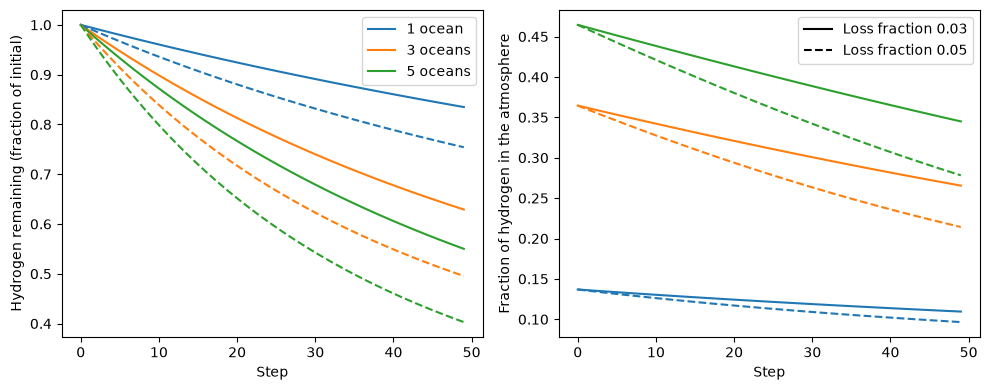

In [8]:
steps = np.arange(NUMBER_OF_STEPS)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 4))
for history_, linestyle in ((history, "-"), (history_5, "--")):
    H_mass_history, H_atmosphere_history = (np.asarray(array) for array in history_[:2])
    for color, index in zip(
        ("C0", "C1", "C2"), (0, NUMBER_OF_PLANETS // 2, NUMBER_OF_PLANETS - 1)
    ):
        oceans = initial_H_mass[index] / OCEAN_H_MASS
        label = (
            f"{oceans:.0f} ocean{'' if round(oceans) == 1 else 's'}" if linestyle == "-" else None
        )
        ax0.plot(
            steps,
            H_mass_history[:, index] / initial_H_mass[index],
            color=color,
            linestyle=linestyle,
            label=label,
        )
        ax1.plot(
            steps,
            H_atmosphere_history[:, index] / H_mass_history[:, index],
            color=color,
            linestyle=linestyle,
        )
ax0.set_xlabel("Step")
ax0.set_ylabel("Hydrogen remaining (fraction of initial)")
ax0.legend()
ax1.legend(
    handles=[
        Line2D([], [], color="k", linestyle="-", label=f"Loss fraction {loss_fraction}"),
        Line2D([], [], color="k", linestyle="--", label="Loss fraction 0.05"),
    ]
)
ax1.set_xlabel("Step")
ax1.set_ylabel("Fraction of hydrogen in the atmosphere")
fig.tight_layout()

## Summary

- Build the model once, and change it in a loop with `update_state` and `update_constraints`, so that the solver is compiled only once. Updated values must broadcast to the shapes they replace (e.g. one value per model of the batch); a different batch size needs a new model.
- Start each solve from the previous solution when consecutive solves are close.
- For the fastest loops, write the loop with `jax.lax.scan` and compile it with `jit`.
- Solve many conditions together as a batch rather than one at a time.
- Changing the species, their models or the solver settings needs a new model, which is compiled again. Compilation can be cached across Python sessions with JAX's [persistent compilation cache](https://docs.jax.dev/en/latest/501/compilation-cache.html), e.g. `jax.config.update("jax_compilation_cache_dir", "jax_cache")`.